In [ ]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from tensorflow.keras import layers, callbacks
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler

In [ ]:
# Load dataset
dataset = pd.read_csv("dataset_temperature.csv")
dataset.head()

,year,month,day,hour,minute,second,recnt_Temperature,recnt_Humidity,Target_Temperature
0,2020.0,2.0,4.0,6.0,30.0,0.0,32.33,80.33,28.6
1,2020.0,2.0,4.0,6.0,40.0,0.0,28.60,82.00,27.4
2,2020.0,2.0,4.0,6.0,50.0,0.0,27.40,83.60,26.4
3,2020.0,2.0,4.0,7.0,0.0,0.0,26.40,84.60,26.0
4,2020.0,2.0,4.0,7.0,10.0,0.0,26.00,85.20,26.4


In [ ]:
# Split data into features (x) and target (y)
x = dataset.iloc[:, :-2].values
y = dataset.iloc[:, -1:].values

# Split data into training and testing sets
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
print('Train set:', x_train.shape, y_train.shape)
print('Test set:', x_test.shape, y_test.shape)

Train set: (10096, 7) (10096, 1)
Test set: (2524, 7) (2524, 1)


In [ ]:
# Menampilkan 5 baris pertama dari x_train
print("x_train:\n", pd.DataFrame(x_train).head(5))

# Menampilkan 5 baris pertama dari x_test
print("x_test:\n", pd.DataFrame(x_test).head(5))

# Menampilkan 5 baris pertama dari y_train
print("y_train:\n", pd.DataFrame(y_train).head(5))

# Menampilkan 5 baris pertama dari y_test
print("y_test:\n", pd.DataFrame(y_test).head(5))

x_train:
         0    1     2     3     4    5     6
0  2020.0  3.0  22.0  15.0  10.0  0.0  27.0
1  2020.0  5.0   4.0  11.0  10.0  0.0  20.0
2  2020.0  2.0  29.0  13.0  10.0  0.0  21.8
3  2020.0  3.0  28.0  23.0  10.0  0.0  33.0
4  2020.0  3.0  18.0   9.0  40.0  0.0  13.0
x_test:
         0    1     2     3     4    5     6
0  2020.0  4.0  23.0  16.0  20.0  0.0  41.6
1  2020.0  5.0   5.0   4.0  20.0  0.0  40.0
2  2020.0  4.0  20.0   2.0  20.0  0.0  54.0
3  2020.0  5.0   8.0  16.0  30.0  0.0  51.6
4  2020.0  4.0  12.0  14.0   0.0  0.0  20.4
y_train:
       0
0  27.0
1  19.8
2  22.0
3  33.8
4  13.6
y_test:
       0
0  42.6
1  37.2
2  51.8
3  52.2
4  21.0


In [ ]:
# Normalisasi fitur (x)
scaler_x = MinMaxScaler()
x_train = scaler_x.fit_transform(x_train)
x_test = scaler_x.transform(x_test)

# Normalisasi target (y)
scaler_y = MinMaxScaler()
y_train = scaler_y.fit_transform(y_train)
y_test = scaler_y.transform(y_test)

# Menampilkan nilai  untuk x
np.set_printoptions(suppress=True)
print("\nShape min (x):", scaler_x.data_min_.shape)
print("Isi data min (x):\n", scaler_x.data_min_)
print("\nShape max (x):", scaler_x.data_max_.shape)
print("Isi data max (x):\n", scaler_x.data_max_)
print("x_train Normalized:\n", x_train)
print("x_test Normalized:\n", x_test)

# Menampilkan nilai untuk y
print("\nShape min (y):", scaler_y.data_min_.shape)
print("Isi data min (y):\n", scaler_y.data_min_)
print("\nShape max (y):", scaler_y.data_max_.shape)
print("Isi data max (y):\n", scaler_y.data_max_)
print("y_train Normalized:\n", y_train)
print("y_test Normalized:\n", y_test)


Shape min (x): (7,)
Isi data min (x):
 [2020.     2.     1.     0.     0.     0.     7.8]

Shape max (x): (7,)
Isi data max (x):
 [2020.     5.    31.    23.    50.     0.    76.2]
x_train Normalized:
 [[0.         0.33333333 0.7        ... 0.2        0.         0.28070175]
 [0.         1.         0.1        ... 0.2        0.         0.17836257]
 [0.         0.         0.93333333 ... 0.2        0.         0.20467836]
 ...
 [0.         0.33333333 0.93333333 ... 0.2        0.         0.29532164]
 [0.         0.         0.86666667 ... 1.         0.         0.28654971]
 [0.         0.66666667 0.36666667 ... 0.8        0.         0.57017544]]
x_test Normalized:
 [[0.         0.66666667 0.73333333 ... 0.4        0.         0.49415205]
 [0.         1.         0.13333333 ... 0.4        0.         0.47076023]
 [0.         0.66666667 0.63333333 ... 0.4        0.         0.6754386 ]
 ...
 [0.         0.66666667 0.86666667 ... 0.4        0.         0.41812865]
 [0.         0.66666667 0.76666667 .

In [ ]:
# Build the model
model = tf.keras.Sequential([
    layers.Dense(16, activation='relu'),
    layers.Dense(16, activation='relu'),
    layers.Dense(1)
])
# Compile the model
model.compile(optimizer='rmsprop', loss='mse', metrics=['mse'])

# Define Early Stopping
early_stopping = callbacks.EarlyStopping(
    monitor='val_loss',  # Memantau nilai loss pada validasi
    patience=10,         # Jika tidak ada peningkatan selama 10 epoch, training dihentikan
    restore_best_weights=True  # Menggunakan bobot terbaik setelah berhenti
)
# Train the model
train_model = model.fit(x_train, y_train, epochs=1000, batch_size=16, validation_data= (x_test, y_test), callbacks=[early_stopping])

# Save the model
model.save('Temperature_predictor_model.keras')

Epoch 1/1000
631/631 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.0991 - mse: 0.0991 - val_loss: 3.2284e-04 - val_mse: 3.2284e-04
Epoch 2/1000
631/631 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 3.5771e-04 - mse: 3.5771e-04 - val_loss: 1.9955e-04 - val_mse: 1.9955e-04
Epoch 3/1000
631/631 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 2.9484e-04 - mse: 2.9484e-04 - val_loss: 2.1549e-04 - val_mse: 2.1549e-04
Epoch 4/1000
631/631 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 2.7143e-04 - mse: 2.7143e-04 - val_loss: 1.7890e-04 - val_mse: 1.7890e-04
Epoch 5/1000
631/631 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 2.5675e-04 - mse: 2.5675e-04 - val_loss: 2.1472e-04 - val_mse: 2.1472e-04
Epoch 6/1000
631/631 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 2.5256e-04 - mse: 2.5256e-04 - val_loss: 1.7402e-04 - val_mse: 1.7402e-04
Epoch 7/1000
631/631 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 2.6404e-04 - mse: 2.6404e-04 - val_loss: 1.8771e-04 - val_mse: 1.8771e-04
Epoch 8/1000
631/631 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - 

In [ ]:
# MSE untuk data training
training_mse = train_model.history['mse']

# MSE untuk data validation
val_mse = train_model.history['val_mse']

# Menampilkan nilai mse pada epoch terakhir
print("Training MSE: ", training_mse[-1])
print("Validation MSE: ", val_mse[-1])

test_mse = model.evaluate(x_test, y_test)
print("Test MSE:", test_mse)

Training MSE:  0.0001896686153486371
Validation MSE:  0.00019503016665112227
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.3672e-04 - mse: 1.3672e-04
Test MSE: [0.000152966778841801, 0.000152966778841801]


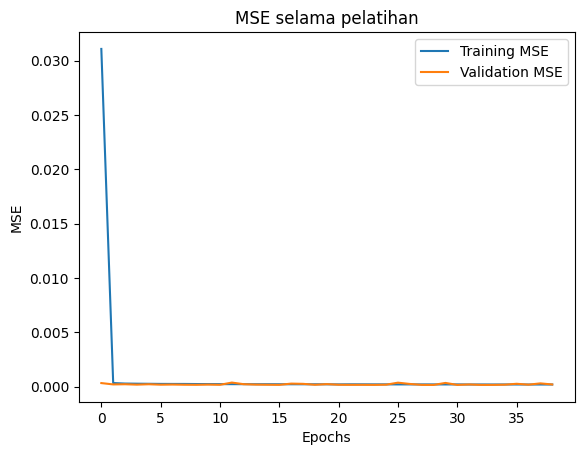

In [ ]:
# Plot training and validation MSE
plt.plot(train_model.history['mse'], label='Training MSE')
plt.plot(train_model.history['val_mse'], label='Validation MSE')
plt.xlabel('Epochs')
plt.ylabel('MSE')
plt.title('MSE selama pelatihan')
plt.legend()
plt.show()

In [ ]:
# Prediksi dan konversi kembali ke skala asli
y_pred = model.predict(x_test)
y_pred_original = scaler_y.inverse_transform(y_pred)  # Kembali ke skala asli
y_actual_original = scaler_y.inverse_transform(y_test)

# Tampilkan beberapa hasil prediksi
print("\nContoh Hasil Prediksi (Temperature):")
for actual, predicted in zip(y_actual_original[:5], y_pred_original[:5]):
    print(f"Actual: {actual[0]:.2f}, Predicted: {predicted[0]:.2f}")

79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step

Contoh Hasil Prediksi (Temperature):
Actual: 42.60, Predicted: 42.12
Actual: 37.20, Predicted: 39.01
Actual: 51.80, Predicted: 53.67
Actual: 52.20, Predicted: 51.82
Actual: 21.00, Predicted: 21.07


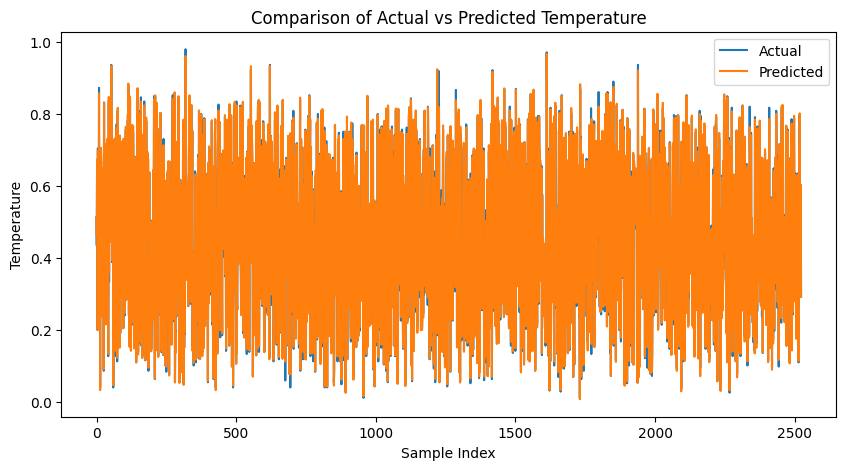

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(y_test, label="Actual")
plt.plot(y_pred, label="Predicted")
plt.xlabel("Sample Index")
plt.ylabel("Temperature")
plt.title("Comparison of Actual vs Predicted Temperature")
plt.legend()
plt.show()

In [ ]:
load_model = tf.keras.models.load_model('Temperature_predictor_model.keras')
converter = tf.lite.TFLiteConverter.from_keras_model(load_model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_model = converter.convert()
open("temperature_predictor.tflite", "wb").write(tflite_model)

Saved artifact at '/tmp/tmp7obwlwnx'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(16, 7), dtype=tf.float32, name='input_layer_12')
Output Type:
  TensorSpec(shape=(16, 1), dtype=tf.float32, name=None)
Captures:
  135187121245264: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135187013963600: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135187004194896: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135187121244688: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135187134432272: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135187134431888: TensorSpec(shape=(), dtype=tf.resource, name=None)


3484

In [ ]:
!xxd -i temperature_predictor.tflite > temperature_predictor.h

In [ ]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, callbacks
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler

In [ ]:
# Load dataset
dataset = pd.read_csv("dataset_humidity.csv")
dataset.head()

,year,month,day,hour,minute,second,recnt_Humidity,recnt_Temperature,Target_Humidity
0,2020.0,2.0,4.0,6.0,30.0,0.0,80.33,32.33,82.0
1,2020.0,2.0,4.0,6.0,40.0,0.0,82.00,28.60,83.6
2,2020.0,2.0,4.0,6.0,50.0,0.0,83.60,27.40,84.6
3,2020.0,2.0,4.0,7.0,0.0,0.0,84.60,26.40,85.2
4,2020.0,2.0,4.0,7.0,10.0,0.0,85.20,26.00,86.0


In [ ]:
# Split data into features (x) and target (y)
x = dataset.iloc[:, :-2].values
y = dataset.iloc[:, -1:].values

# Split data into training and testing sets
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
print('Train set:', x_train.shape, y_train.shape)
print('Test set:', x_test.shape, y_test.shape)

Train set: (10096, 7) (10096, 1)
Test set: (2524, 7) (2524, 1)


In [ ]:
# Menampilkan 5 baris pertama dari x_train
print("x_train:\n", pd.DataFrame(x_train).head(5))

# Menampilkan 5 baris pertama dari x_test
print("x_test:\n", pd.DataFrame(x_test).head(5))

# Menampilkan 5 baris pertama dari y_train
print("y_train:\n", pd.DataFrame(y_train).head(5))

# Menampilkan 5 baris pertama dari y_test
print("y_test:\n", pd.DataFrame(y_test).head(5))

x_train:
         0    1     2     3     4    5      6
0  2020.0  3.0  22.0  15.0  10.0  0.0   93.0
1  2020.0  5.0   4.0  11.0  10.0  0.0  103.6
2  2020.0  2.0  29.0  13.0  10.0  0.0   90.4
3  2020.0  3.0  28.0  23.0  10.0  0.0   81.0
4  2020.0  3.0  18.0   9.0  40.0  0.0  102.8
x_test:
         0    1     2     3     4    5     6
0  2020.0  4.0  23.0  16.0  20.0  0.0  88.4
1  2020.0  5.0   5.0   4.0  20.0  0.0  93.8
2  2020.0  4.0  20.0   2.0  20.0  0.0  83.4
3  2020.0  5.0   8.0  16.0  30.0  0.0  87.0
4  2020.0  4.0  12.0  14.0   0.0  0.0  91.8
y_train:
        0
0   93.0
1  104.2
2   90.0
3   81.0
4  101.8
y_test:
       0
0  88.0
1  95.2
2  84.4
3  86.4
4  91.0


In [ ]:
# Normalisasi fitur (x)
scaler_x = MinMaxScaler()
x_train = scaler_x.fit_transform(x_train)
x_test = scaler_x.transform(x_test)

# Normalisasi target (y)
scaler_y = MinMaxScaler()
y_train = scaler_y.fit_transform(y_train)
y_test = scaler_y.transform(y_test)

# Menampilkan nilai  untuk x
np.set_printoptions(suppress=True)
print("\nShape min (x):", scaler_x.data_min_.shape)
print("Isi data min (x):\n", scaler_x.data_min_)
print("\nShape max (x):", scaler_x.data_max_.shape)
print("Isi data max (x):\n", scaler_x.data_max_)
print("x_train Normalized:\n", x_train)
print("x_test Normalized:\n", x_test)

# Menampilkan nilai untuk y
print("\nShape min (y):", scaler_y.data_min_.shape)
print("Isi data min (y):\n", scaler_y.data_min_)
print("\nShape max (y):", scaler_y.data_max_.shape)
print("Isi data max (y):\n", scaler_y.data_max_)
print("y_train Normalized:\n", y_train)
print("y_test Normalized:\n", y_test)


Shape min (x): (7,)
Isi data min (x):
 [2020.    2.    1.    0.    0.    0.   70.]

Shape max (x): (7,)
Isi data max (x):
 [2020.     5.    31.    23.    50.     0.   107.2]
x_train Normalized:
 [[0.         0.33333333 0.7        ... 0.2        0.         0.61827957]
 [0.         1.         0.1        ... 0.2        0.         0.90322581]
 [0.         0.         0.93333333 ... 0.2        0.         0.5483871 ]
 ...
 [0.         0.33333333 0.93333333 ... 0.2        0.         0.39247312]
 [0.         0.         0.86666667 ... 1.         0.         0.57526882]
 [0.         0.66666667 0.36666667 ... 0.8        0.         0.37634409]]
x_test Normalized:
 [[0.         0.66666667 0.73333333 ... 0.4        0.         0.49462366]
 [0.         1.         0.13333333 ... 0.4        0.         0.63978495]
 [0.         0.66666667 0.63333333 ... 0.4        0.         0.36021505]
 ...
 [0.         0.66666667 0.86666667 ... 0.4        0.         0.69354839]
 [0.         0.66666667 0.76666667 ... 0.8 

In [ ]:
# Build the model
model = tf.keras.Sequential([
    layers.Dense(16, activation='relu'),
    layers.Dense(16, activation='relu'),
    layers.Dense(1)
])
# Compile the model
model.compile(optimizer='rmsprop', loss='mse', metrics=['mse'])

# Define Early Stopping
early_stopping = callbacks.EarlyStopping(
    monitor='val_loss',  # Memantau nilai loss pada validasi
    patience=10,         # Jika tidak ada peningkatan selama 10 epoch, training dihentikan
    restore_best_weights=True  # Menggunakan bobot terbaik setelah berhenti
)
# Train the model
train_model = model.fit(x_train, y_train, epochs=1000, batch_size=16, validation_data= (x_test, y_test), callbacks=[early_stopping])

# Save the model
model.save('humidity_predictor_model.keras')

Epoch 1/1000
631/631 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 0.0658 - mse: 0.0658 - val_loss: 3.7010e-04 - val_mse: 3.7010e-04
Epoch 2/1000
631/631 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 4.1948e-04 - mse: 4.1948e-04 - val_loss: 2.7902e-04 - val_mse: 2.7902e-04
Epoch 3/1000
631/631 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 3.6595e-04 - mse: 3.6595e-04 - val_loss: 3.4696e-04 - val_mse: 3.4696e-04
Epoch 4/1000
631/631 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 3.4361e-04 - mse: 3.4361e-04 - val_loss: 5.3216e-04 - val_mse: 5.3216e-04
Epoch 5/1000
631/631 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 3.3494e-04 - mse: 3.3494e-04 - val_loss: 2.9590e-04 - val_mse: 2.9590e-04
Epoch 6/1000
631/631 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 3.1898e-04 - mse: 3.1898e-04 - val_loss: 9.2702e-04 - val_mse: 9.2702e-04
Epoch 7/1000
631/631 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 3.1170e-04 - mse: 3.1170e-04 - val_loss: 2.4984e-04 - val_mse: 2.4984e-04
Epoch 8/1000
631/631 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - 

In [ ]:
# MSE untuk data training
training_mse = train_model.history['mse']

# MSE untuk data validation
val_mse = train_model.history['val_mse']

# Menampilkan nilai mse pada epoch terakhir
print("Training MSE: ", training_mse[-1])
print("Validation MSE: ", val_mse[-1])
test_mse = model.evaluate(x_test, y_test)
print("Test MSE:", test_mse)


Training MSE:  0.00024609494721516967
Validation MSE:  0.0002413215843262151
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 2.0550e-04 - mse: 2.0550e-04
Test MSE: [0.00021034236124251038, 0.00021034236124251038]


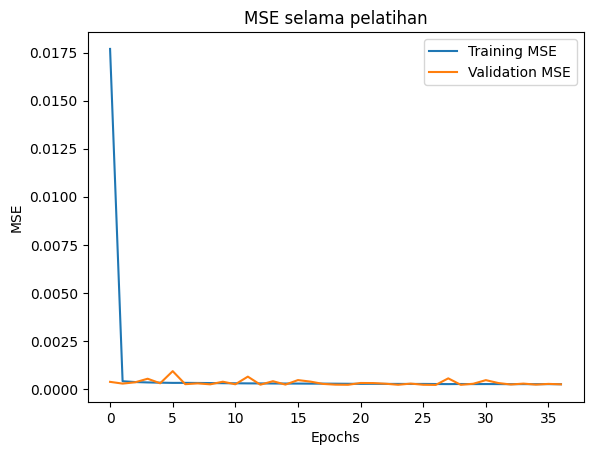

In [ ]:
# Plot training and validation MSE
plt.plot(train_model.history['mse'], label='Training MSE')
plt.plot(train_model.history['val_mse'], label='Validation MSE')
plt.xlabel('Epochs')
plt.ylabel('MSE')
plt.title('MSE selama pelatihan')
plt.legend()
plt.show()

In [ ]:
# Prediksi dan konversi kembali ke skala asli
y_pred = model.predict(x_test)
y_pred_original = scaler_y.inverse_transform(y_pred)  # Kembali ke skala asli
y_actual_original = scaler_y.inverse_transform(y_test)

# Tampilkan beberapa hasil prediksi
print("\nContoh Hasil Prediksi (Humidity):")
for actual, predicted in zip(y_actual_original[:5], y_pred_original[:5]):
    print(f"Actual: {actual[0]:.2f}, Predicted: {predicted[0]:.2f}")

79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step

Contoh Hasil Prediksi (Humidity):
Actual: 88.00, Predicted: 88.25
Actual: 95.20, Predicted: 94.39
Actual: 84.40, Predicted: 83.60
Actual: 86.40, Predicted: 86.89
Actual: 91.00, Predicted: 91.50


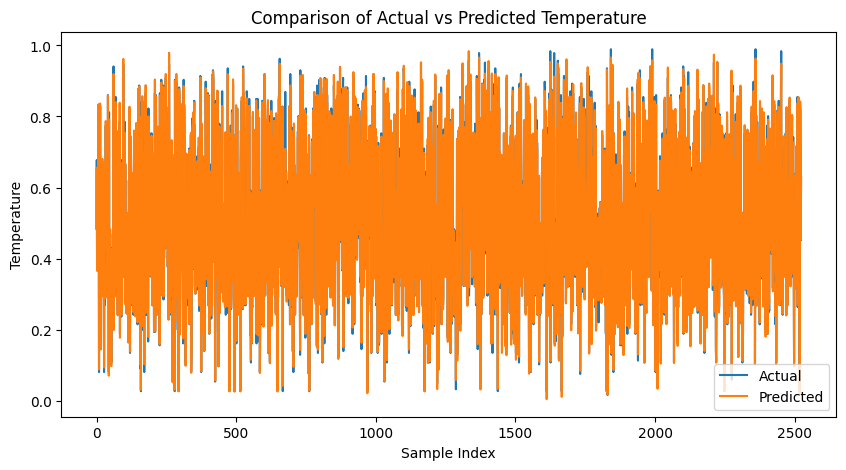

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(y_test, label="Actual")
plt.plot(y_pred, label="Predicted")
plt.xlabel("Sample Index")
plt.ylabel("Temperature")
plt.title("Comparison of Actual vs Predicted Temperature")
plt.legend()
plt.show()

In [ ]:
load_model = tf.keras.models.load_model('humidity_predictor_model.keras')
converter = tf.lite.TFLiteConverter.from_keras_model(load_model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_model = converter.convert()
open("humidity_predictor.tflite", "wb").write(tflite_model)

Saved artifact at '/tmp/tmp46a1imbf'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(16, 7), dtype=tf.float32, name='input_layer_15')
Output Type:
  TensorSpec(shape=(16, 1), dtype=tf.float32, name=None)
Captures:
  135186982763792: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135186982759376: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135186982756688: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135186982763600: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135186982760336: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135187036296720: TensorSpec(shape=(), dtype=tf.resource, name=None)


3484

In [ ]:
!xxd -i humidity_predictor.tflite > humidity_predictor.h